# Linear Regression

In [1]:
#import libraries for linear regression
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np


## Load data

In [4]:
data_frame = pd.read_excel('FuelConsumptionCo2.xlsx')
data_frame.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2022,Acura,ILX,Compact,2.4,4,AM8,Z,9.9,7.0,8.6,33,200
1,2022,Acura,MDX SH-AWD,SUV: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263
2,2022,Acura,RDX SH-AWD,SUV: Small,2.0,4,AS10,Z,11.0,8.6,9.9,29,232
3,2022,Acura,RDX SH-AWD A-SPEC,SUV: Small,2.0,4,AS10,Z,11.3,9.1,10.3,27,242
4,2022,Acura,TLX SH-AWD,Compact,2.0,4,AS10,Z,11.2,8.0,9.8,29,230


In [5]:
data_frame.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000
mean,2022.0,3.201058,5.670899,12.515767,9.374603,11.102222,27.222222,259.410582
std,0.0,1.374256,1.932837,3.452369,2.290217,2.878074,7.684409,64.486225
min,2022.0,1.200000,3.000000,4.000000,3.900000,4.000000,11.000000,94.000000
25%,2022.0,2.000000,4.000000,10.200000,7.700000,9.100000,22.000000,214.000000
50%,2022.0,3.000000,6.000000,12.200000,9.200000,10.800000,26.000000,258.000000
75%,2022.0,3.800000,6.000000,14.700000,10.700000,12.900000,31.000000,301.000000
max,2022.0,8.000000,16.000000,30.300000,20.900000,26.100000,71.000000,608.000000


In [7]:
cdf = data_frame[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS']]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.4,4,8.6,200
1,3.5,6,11.2,263
2,2.0,4,9.9,232
3,2.0,4,10.3,242
4,2.0,4,9.8,230
5,2.0,4,9.8,231
6,3.0,6,11.0,256
7,3.0,6,11.2,261
8,2.0,4,8.7,205


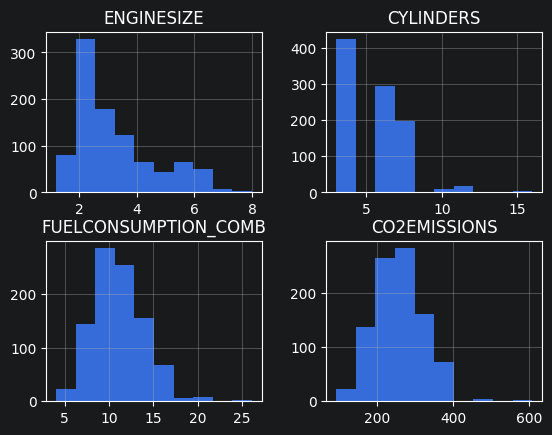

In [9]:
viz = cdf[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS']]
viz.hist()
plt.show()

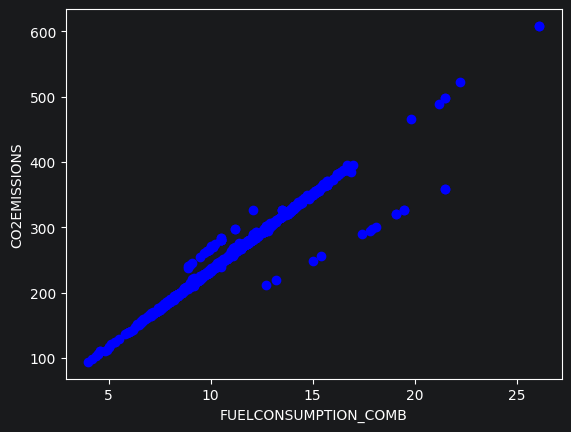

In [10]:
# Scatter plot fuel consuption vs co2 emissions
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS, color='blue')
plt.xlabel('FUELCONSUMPTION_COMB')
plt.ylabel('CO2EMISSIONS')
plt.show()

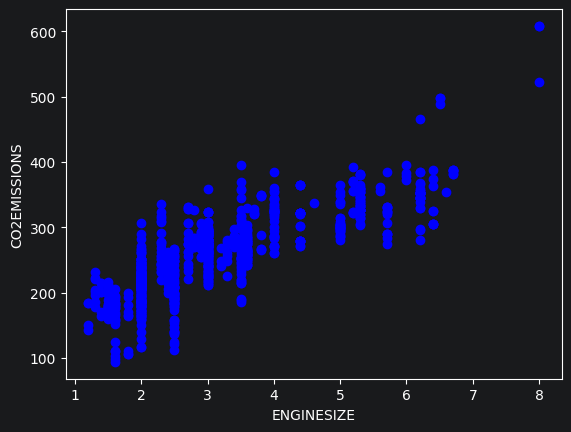

In [11]:
# Scatter plot energisize vs co2 emissions
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color='blue')
plt.xlabel('ENGINESIZE')
plt.ylabel('CO2EMISSIONS')
plt.show()

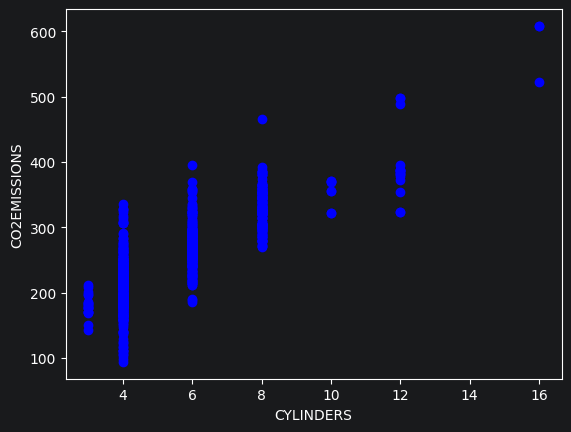

In [12]:
# Scatter plot fuel cylinder vs co2 emissions
plt.scatter(cdf.CYLINDERS, cdf.CO2EMISSIONS, color='blue')
plt.xlabel('CYLINDERS')
plt.ylabel('CO2EMISSIONS')
plt.show()

In [13]:
# create mask to select the data to train the model
msk = np.random.rand(len(data_frame)) <=  0.8
msk

array([False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True, False,  True,
       False,  True, False,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True, False,  True, False,  True,  True,  True,
        True, False, False, False,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True, False,
       False,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True, False,  True, False,  True,  True, False,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [16]:
train_data = cdf[msk]
train_data

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
1,3.5,6,11.2,263
2,2.0,4,9.9,232
3,2.0,4,10.3,242
4,2.0,4,9.8,230
5,2.0,4,9.8,231
...,...,...,...,...
940,2.0,4,9.4,219
941,2.0,4,9.4,219
942,2.0,4,9.9,232
943,2.0,4,10.1,236


In [17]:
test_data = cdf[~msk]
test_data

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.4,4,8.6,200
14,4.0,8,11.5,271
16,5.2,12,13.8,324
18,4.0,8,11.5,270
20,2.0,4,8.2,190
...,...,...,...,...
917,3.6,6,12.2,286
919,3.6,6,11.7,275
924,1.5,4,6.8,159
930,1.5,4,8.5,200


In [18]:
from sklearn import linear_model
regression = linear_model.LinearRegression()
train_x = np.asanyarray(train_data[['ENGINESIZE']])
train_y = np.asanyarray(train_data[['CO2EMISSIONS']])
regression.fit(train_x, train_y)

LinearRegression()

In [19]:
print(f'Coefficients: {regression.coef_}')
print(f'Intercept: {regression.intercept_}')

Coefficients: [[39.22995098]]
Intercept: [135.14576965]


Text(0, 0.5, 'EMISSIONS')

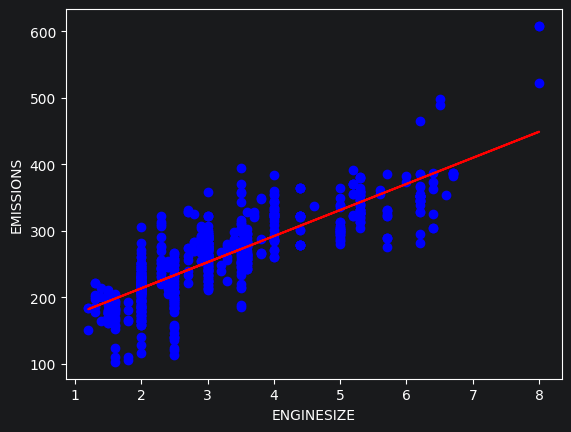

In [23]:
# Linear regression
plt.scatter(train_data.ENGINESIZE, train_data.CO2EMISSIONS, color='blue')
plt.plot(train_x, regression.coef_[0][0]*train_x + regression.intercept_[0], '-r')
plt.xlabel('ENGINESIZE')
plt.ylabel('EMISSIONS')

In [24]:
# Error estimation
from sklearn.metrics import r2_score
test_x = np.asanyarray(test_data[['ENGINESIZE']])
test_y = np.asanyarray(test_data[['CO2EMISSIONS']])
test_y_hat = regression.predict(test_x)


In [25]:
test_y_hat

array([[229.29765199],
       [292.06557355],
       [339.14151472],
       [292.06557355],
       [213.6056716 ],
       [213.6056716 ],
       [213.6056716 ],
       [252.83562258],
       [252.83562258],
       [213.6056716 ],
       [370.5254755 ],
       [370.5254755 ],
       [213.6056716 ],
       [213.6056716 ],
       [252.83562258],
       [213.6056716 ],
       [252.83562258],
       [252.83562258],
       [307.75755394],
       [307.75755394],
       [307.75755394],
       [307.75755394],
       [252.83562258],
       [213.6056716 ],
       [190.06770102],
       [190.06770102],
       [241.06663728],
       [252.83562258],
       [276.37359316],
       [213.6056716 ],
       [276.37359316],
       [213.6056716 ],
       [378.3714657 ],
       [378.3714657 ],
       [193.99069611],
       [193.99069611],
       [241.06663728],
       [190.06770102],
       [343.06450982],
       [378.3714657 ],
       [276.37359316],
       [276.37359316],
       [358.75649021],
       [276

In [29]:
print(f'Mean absolute error: {np.mean(np.absolute(test_y_hat - test_y))}')
print(f'Residual sum of squares (MSE): {np.mean(test_y - test_y_hat) ** 2}')
print(f'R2-score:  {r2_score(test_y_hat, test_y)}')

Mean absolute error: 31.19809153186694
Residual sum of squares (MSE): 41.73388928683451
R2-score:  0.4532105371882541


In [42]:
cdf2 = data_frame[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY','FUELCONSUMPTION_COMB', 'CO2EMISSIONS']]
cdf2.head(9)


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.4,4,9.9,7.0,8.6,200
1,3.5,6,12.6,9.4,11.2,263
2,2.0,4,11.0,8.6,9.9,232
3,2.0,4,11.3,9.1,10.3,242
4,2.0,4,11.2,8.0,9.8,230
5,2.0,4,11.3,8.1,9.8,231
6,3.0,6,12.3,9.4,11.0,256
7,3.0,6,12.3,9.8,11.2,261
8,2.0,4,10.0,7.2,8.7,205


In [43]:
train_data = cdf2[msk]
train_data
test_data = cdf2[~msk]
test_data

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.4,4,9.9,7.0,8.6,200
14,4.0,8,13.0,9.8,11.5,271
16,5.2,12,16.4,10.7,13.8,324
18,4.0,8,13.1,9.6,11.5,270
20,2.0,4,9.1,7.0,8.2,190
...,...,...,...,...,...,...
917,3.6,6,13.8,10.2,12.2,286
919,3.6,6,13.1,10.0,11.7,275
924,1.5,4,7.7,5.7,6.8,159
930,1.5,4,9.5,7.4,8.5,200


In [44]:
x = np.asanyarray(train_data[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']])
y = np.asanyarray(train_data[['CO2EMISSIONS']])
regression.fit(x, y)
print(f'Coefficients: {regression.coef_}')
print(f'Intercept: {regression.intercept_}')

Coefficients: [[ 0.46526727  3.82365449 19.2194863 ]]
Intercept: [23.07205952]


CO2EMISSIONS = 23.07205952 + 0.46526727 * (ENGINESIZE) + 3.82365449 * (CYLINDERS) + 19.2194863 * (FUELCONSUMPTION_COMB)

In [47]:
y_hat = regression.predict(test_data[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']])
x = np.asanyarray(test_data[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']])
y = np.asanyarray(test_data[['CO2EMISSIONS']])

/Users/hugoalonzo/ds_env/lib/python3.9/site-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [49]:
# Error evaluation
print(f"Mean absolute error: {np.mean(np.absolute(y_hat - y)): .2f}")
print(f"Residual sum of squares (MSE): {np.mean((y_hat - y)**2): .2f}")
print(f"R2-score: {r2_score(y_hat, y): .2f}")

Mean absolute error:  6.84
Residual sum of squares (MSE):  132.04
R2-score:  0.96


# Other regression models

## Lineal regression

In [50]:
def pol_grade_1(x, beta_0, beta_1):
    y = beta_0 + beta_1 * x
    return y

In [51]:
x = np.arange(-5.0, 5.0, 0.1)
y = pol_grade_1(x, 0, 1)
y_noise = np.random.normal(0, 1, size=x.size)
y_data = y + y_noise

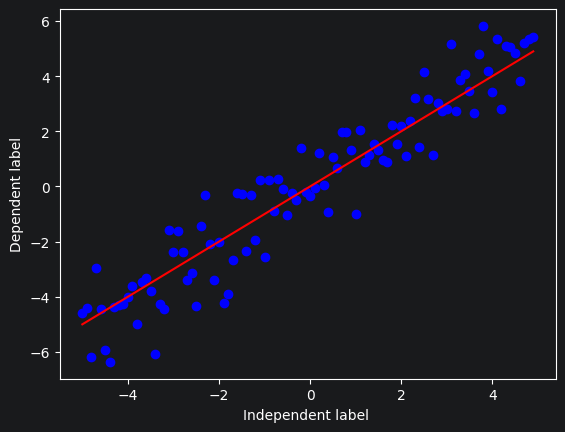

In [52]:
plt.plot(x, y_data, 'bo')
plt.plot(x, y, 'r')
plt.xlabel('Independent label ')
plt.ylabel('Dependent label')
plt.show()


In [53]:
from scipy.optimize import curve_fit
popt, pcov = curve_fit(pol_grade_1, x, y_data)

In [54]:
print(f'beta_0 =  {popt[0]}, beta_1 =  {popt[1]}')

beta_0 =  0.013778500056956022, beta_1 =  1.0608741122309187


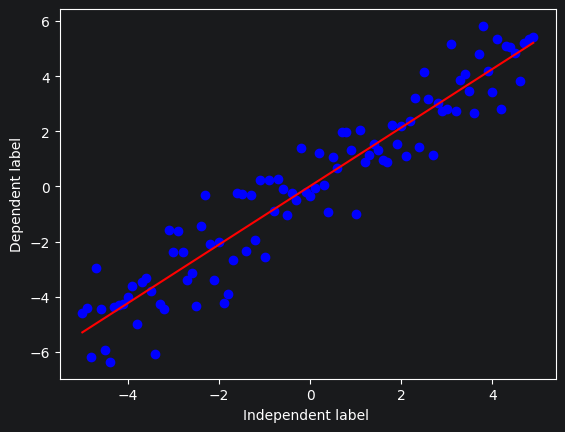

In [55]:
y_adjust = pol_grade_1(x, popt[0], popt[1])
plt.plot(x, y_data, 'bo')
plt.plot(x, y_adjust, 'r')
plt.xlabel('Independent label ')
plt.ylabel('Dependent label')
plt.show()

## Cubic regression

In [58]:
def cubic_polynomic(x, beta_0, beta_1, beta_2, beta_3):
    y = beta_0 + beta_1 * x + beta_2 * x ** 2 + beta_3 * x**3
    return y

In [62]:
x = np.arange(-5.0, 5.0, 0.1 )
y = cubic_polynomic(x, 3, 1, 1, 1)
y_noise = 20 * np.random.normal(0, 1, size=x.size)
y_data = y + y_noise

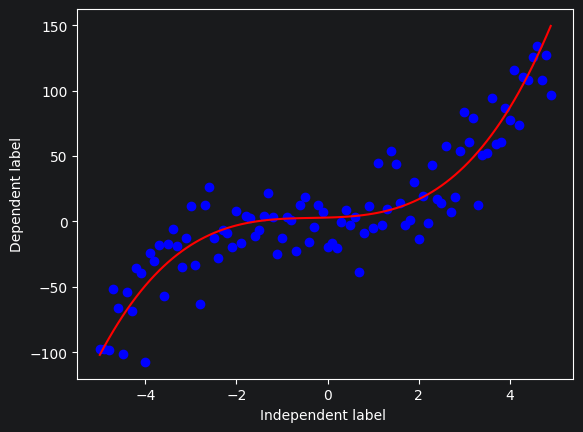

In [63]:
plt.plot(x, y_data, 'bo')
plt.plot(x, y, 'r')
plt.xlabel('Independent label ')
plt.ylabel('Dependent label')
plt.show()

In [69]:
msk = np.random.rand(len(x)) <= 0.8
msk

array([ True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True, False,  True, False,
       False,  True,  True,  True,  True, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True, False,  True,  True,  True,  True,
       False,  True,  True, False,  True, False,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True, False,  True,  True,  True,
       False,  True,  True, False,  True,  True, False,  True,  True,
       False])

In [70]:
train_x = x[msk]
test_x = x[~msk]
train_y = y_data[msk]
test_y = y_data[~msk]

In [72]:
popt, pcov = curve_fit(cubic_polynomic, train_x, train_y)
print(f'Coefficients: beta_0 = {popt[0]}, beta_1 = {popt[1]}, beta_2 = {popt[2]}, beta_3 = {popt[3]}')

Coefficients: beta_0 = 2.0316417634540227, beta_1 = 2.71661013591668, beta_2 = 1.0752986020729747, beta_3 = 0.8372451284294131


In [73]:
y_hat = cubic_polynomic(test_x, *popt)

In [74]:
# Error evaluation
print(f"Mean absolute error: {np.mean(np.absolute(y_hat - test_y)): .2f}")
print(f"Residual sum of squares (MSE): {np.mean((y_hat - test_y)**2): .2f}")
print(f"R2-score: {r2_score(y_hat, test_y): .2f}")

Mean absolute error:  13.29
Residual sum of squares (MSE):  326.80
R2-score:  0.87


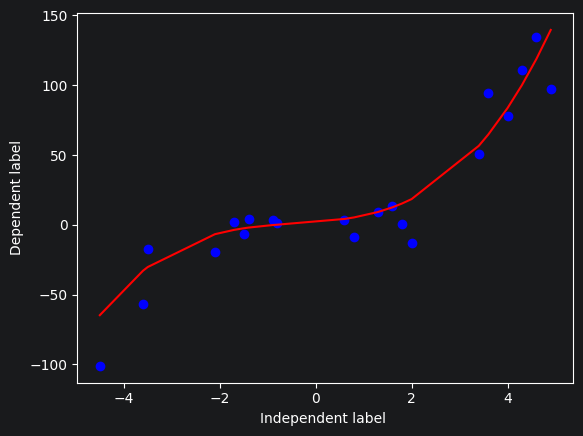

In [75]:
plt.plot(test_x, test_y, 'bo')
plt.plot(test_x, y_hat, 'r')
plt.xlabel('Independent label ')
plt.ylabel('Dependent label')
plt.show()